In [1]:
import numpy as np
import pandas as pd

In [2]:
train = pd.read_csv('train.csv', encoding='cp1252')
test = pd.read_csv('test.csv', encoding='cp1252')

In [3]:
train.head()

,textID,text,selected_text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km²),Density (P/Km²)
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral,morning,0-20,Afghanistan,38928346,652860.0,60
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative,noon,21-30,Albania,2877797,27400.0,105
2,088c60f138,my boss is bullying me...,bullying me,negative,night,31-45,Algeria,43851044,2381740.0,18
3,9642c003ef,what interview! leave me alone,leave me alone,negative,morning,46-60,Andorra,77265,470.0,164
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative,noon,60-70,Angola,32866272,1246700.0,26


In [4]:
train.shape

(27481, 10)

In [5]:
test.head()

,textID,text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km²),Density (P/Km²)
0,f87dea47db,Last session of the day http://twitpic.com/67ezh,neutral,morning,0-20,Afghanistan,38928346.0,652860.0,60.0
1,96d74cb729,Shanghai is also really exciting (precisely -...,positive,noon,21-30,Albania,2877797.0,27400.0,105.0
2,eee518ae67,"Recession hit Veronique Branquinho, she has to...",negative,night,31-45,Algeria,43851044.0,2381740.0,18.0
3,01082688c6,happy bday!,positive,morning,46-60,Andorra,77265.0,470.0,164.0
4,33987a8ee5,http://twitpic.com/4w75p - I like it!!,positive,noon,60-70,Angola,32866272.0,1246700.0,26.0


In [6]:
test.shape

(4815, 9)

In [7]:
# 1. Data Cleaning
# 2. EDA
# 3. Text Preprocessing
# 4. Model building
# 5. Evaluation
# 6. Improvement
# 7. Website
# 8. Deploy

# 1. Data Cleaning

In [8]:
# train = train[['text', 'sentiment']]

In [9]:
# train.head()

In [10]:
# test = test[['text', 'sentiment']]

In [11]:
# pd.concat([test, train], axis=0, ignore_index=True)

In [12]:
# df = pd.concat([test, train], axis=0, ignore_index=True)
# df.head()

In [13]:
# df.shape

In [14]:
df = train[['selected_text', 'sentiment']].copy()

In [15]:
np.random.seed(50)
df.sample(10000).reset_index(drop=True)

,selected_text,sentiment
0,just watch evan longoria,neutral
1,His beard is addressed in this week`s LOLs.,neutral
2,Pretty amazing weekend so far but its bedtime...,neutral
3,SO frustrated!!,negative
4,never,negative
...,...,...
9995,thought I was going to have a fun day,neutral
9996,Had a totally chilled out day relaxing in the ...,neutral
9997,"i love pink, and i don`t care. today i shall n...",positive
9998,I should post some photos of my robots ok - o...,neutral


In [16]:
np.random.seed(50)
df = df.sample(10000).reset_index(drop=True)

In [17]:
df.head()

,selected_text,sentiment
0,just watch evan longoria,neutral
1,His beard is addressed in this week`s LOLs.,neutral
2,Pretty amazing weekend so far but its bedtime...,neutral
3,SO frustrated!!,negative
4,never,negative


In [18]:
# df.rename(columns = {'sentiment': 'target'})
df.rename(columns={'selected_text': 'text', 'sentiment': 'target'})

,text,target
0,just watch evan longoria,neutral
1,His beard is addressed in this week`s LOLs.,neutral
2,Pretty amazing weekend so far but its bedtime...,neutral
3,SO frustrated!!,negative
4,never,negative
...,...,...
9995,thought I was going to have a fun day,neutral
9996,Had a totally chilled out day relaxing in the ...,neutral
9997,"i love pink, and i don`t care. today i shall n...",positive
9998,I should post some photos of my robots ok - o...,neutral


In [19]:
# df.rename(columns = {'sentiment': 'target'}, inplace=True)
df.rename(columns={'selected_text': 'text', 'sentiment': 'target'}, inplace=True)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    9999 non-null   object
 1   target  10000 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB


In [21]:
df.isnull().sum()

text      1
target    0
dtype: int64

In [22]:
df.dropna(inplace=True)

In [23]:
df.isnull().sum()

text      0
target    0
dtype: int64

In [24]:
df.duplicated().sum()

np.int64(1459)

In [25]:
df.drop_duplicates(keep='first')

,text,target
0,just watch evan longoria,neutral
1,His beard is addressed in this week`s LOLs.,neutral
2,Pretty amazing weekend so far but its bedtime...,neutral
3,SO frustrated!!,negative
4,never,negative
...,...,...
9995,thought I was going to have a fun day,neutral
9996,Had a totally chilled out day relaxing in the ...,neutral
9997,"i love pink, and i don`t care. today i shall n...",positive
9998,I should post some photos of my robots ok - o...,neutral


In [26]:
df.drop_duplicates(keep='first').reset_index(drop=True)

,text,target
0,just watch evan longoria,neutral
1,His beard is addressed in this week`s LOLs.,neutral
2,Pretty amazing weekend so far but its bedtime...,neutral
3,SO frustrated!!,negative
4,never,negative
...,...,...
8535,thought I was going to have a fun day,neutral
8536,Had a totally chilled out day relaxing in the ...,neutral
8537,"i love pink, and i don`t care. today i shall n...",positive
8538,I should post some photos of my robots ok - o...,neutral


In [27]:
df = df.drop_duplicates(keep='first').reset_index(drop=True)

In [28]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [29]:
encoder.fit_transform(df['target'])

array([1, 1, 1, ..., 2, 1, 1], shape=(8540,))

In [30]:
df.head(10)

,text,target
0,just watch evan longoria,neutral
1,His beard is addressed in this week`s LOLs.,neutral
2,Pretty amazing weekend so far but its bedtime...,neutral
3,SO frustrated!!,negative
4,never,negative
5,y missed,negative
6,Thanks,positive
7,Digging the ideas behind railsbridge (http://r...,neutral
8,My ear are popping.,neutral
9,Okay I`m seriously bored. I have nothing to do...,negative


In [31]:
df['target'] = encoder.fit_transform(df['target'])

In [32]:
df.head(10)

,text,target
0,just watch evan longoria,1
1,His beard is addressed in this week`s LOLs.,1
2,Pretty amazing weekend so far but its bedtime...,1
3,SO frustrated!!,0
4,never,0
5,y missed,0
6,Thanks,2
7,Digging the ideas behind railsbridge (http://r...,1
8,My ear are popping.,1
9,Okay I`m seriously bored. I have nothing to do...,0


In [33]:
# 1-> neutral, 2->positive, 0->negative

In [34]:
df

,text,target
0,just watch evan longoria,1
1,His beard is addressed in this week`s LOLs.,1
2,Pretty amazing weekend so far but its bedtime...,1
3,SO frustrated!!,0
4,never,0
...,...,...
8535,thought I was going to have a fun day,1
8536,Had a totally chilled out day relaxing in the ...,1
8537,"i love pink, and i don`t care. today i shall n...",2
8538,I should post some photos of my robots ok - o...,1


In [35]:
df.shape

(8540, 2)

# 2. EDA

In [36]:
df.head()

,text,target
0,just watch evan longoria,1
1,His beard is addressed in this week`s LOLs.,1
2,Pretty amazing weekend so far but its bedtime...,1
3,SO frustrated!!,0
4,never,0


In [37]:
df['target'].value_counts()

target
1    3961
0    2345
2    2234
Name: count, dtype: int64

([<matplotlib.patches.Wedge at 0x2aa6f303230>,
 [Text(0.12476915522592977, 1.092901028412092, 'neutral'),
  Text(-0.8853777807112253, -0.6527680946728827, 'positive'),
  Text(0.7489809531758295, -0.8056224498981058, 'negative')],
 [Text(0.06805590285050714, 0.5961278336793228, '46.38'),
  Text(-0.4829333349333956, -0.35605532436702686, '27.46'),
  Text(0.4085350653686342, -0.4394304272171486, '26.16')])

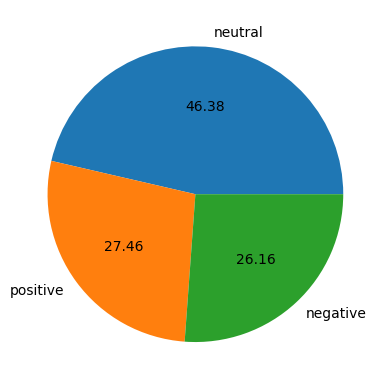

In [38]:
import matplotlib.pyplot as plt
plt.pie(df['target'].value_counts(), labels=['neutral', 'positive', 'negative'], autopct='%0.2f')

In [39]:
import nltk

In [40]:
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Vishwanath\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [41]:
df['text'].apply(len)

0        24
1        43
2       100
3        15
4         5
       ... 
8535     37
8536    111
8537    135
8538     89
8539     60
Name: text, Length: 8540, dtype: int64

In [42]:
df['num_characters'] = df['text'].apply(len)

In [43]:
df.head()

,text,target,num_characters
0,just watch evan longoria,1,24
1,His beard is addressed in this week`s LOLs.,1,43
2,Pretty amazing weekend so far but its bedtime...,1,100
3,SO frustrated!!,0,15
4,never,0,5


In [44]:
df['text'].apply(lambda x: len(nltk.word_tokenize(x)))

0        4
1       11
2       20
3        4
4        1
        ..
8535     9
8536    23
8537    31
8538    24
8539    13
Name: text, Length: 8540, dtype: int64

In [45]:
df['num_words'] = df['text'].apply(lambda x: len(nltk.word_tokenize(x)))

In [46]:
df.head()

,text,target,num_characters,num_words
0,just watch evan longoria,1,24,4
1,His beard is addressed in this week`s LOLs.,1,43,11
2,Pretty amazing weekend so far but its bedtime...,1,100,20
3,SO frustrated!!,0,15,4
4,never,0,5,1


In [47]:
df['text'].apply(lambda x: len(nltk.sent_tokenize(x)))

0       1
1       1
2       2
3       2
4       1
       ..
8535    1
8536    2
8537    3
8538    2
8539    2
Name: text, Length: 8540, dtype: int64

In [48]:
df['num_sentences'] = df['text'].apply(lambda x: len(nltk.sent_tokenize(x)))

In [49]:
df.head()

,text,target,num_characters,num_words,num_sentences
0,just watch evan longoria,1,24,4,1
1,His beard is addressed in this week`s LOLs.,1,43,11,1
2,Pretty amazing weekend so far but its bedtime...,1,100,20,2
3,SO frustrated!!,0,15,4,2
4,never,0,5,1,1


In [50]:
df[['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,8540.000000,8540.000000,8540.000000
mean,42.006792,9.982084,1.372131
std,36.084002,8.542710,0.813961
min,2.000000,1.000000,1.000000
25%,13.000000,3.000000,1.000000
50%,29.000000,7.000000,1.000000
75%,63.000000,15.000000,2.000000
max,143.000000,106.000000,34.000000


In [51]:
df[df['target']==0][['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,2345.000000,2345.000000,2345.000000
mean,23.565458,5.811087,1.146695
std,24.145271,5.710347,0.445654
min,2.000000,1.000000,1.000000
25%,8.000000,2.000000,1.000000
50%,16.000000,4.000000,1.000000
75%,28.000000,7.000000,1.000000
max,138.000000,35.000000,6.000000


In [52]:
df[df['target']==1][['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,3961.000000,3961.000000,3961.000000
mean,63.185307,14.880333,1.600606
std,36.048887,8.671521,1.022494
min,2.000000,1.000000,1.000000
25%,33.000000,8.000000,1.000000
50%,58.000000,13.000000,1.000000
75%,91.000000,21.000000,2.000000
max,143.000000,106.000000,34.000000


In [53]:
df[df['target']==2][['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,2234.000000,2234.00000,2234.000000
mean,23.813787,5.67547,1.203671
std,24.054559,5.66594,0.544619
min,2.000000,1.00000,1.000000
25%,9.000000,2.00000,1.000000
50%,16.000000,4.00000,1.000000
75%,28.000000,7.00000,1.000000
max,141.000000,40.00000,7.000000


In [54]:
import seaborn as sns

In [55]:
df[df['target']==0]['num_characters']

3        15
4         5
5         8
9        82
11        8
       ... 
8522      8
8523    104
8526     29
8527     26
8534     33
Name: num_characters, Length: 2345, dtype: int64

<Axes: xlabel='num_characters', ylabel='Count'>

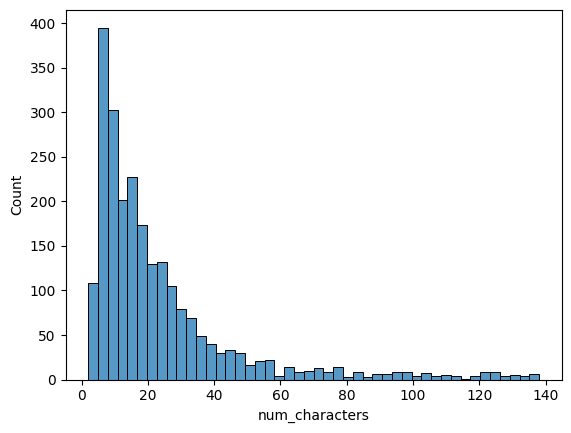

In [56]:
sns.histplot(df[df['target']==0]['num_characters'])

<Axes: xlabel='num_characters', ylabel='Count'>

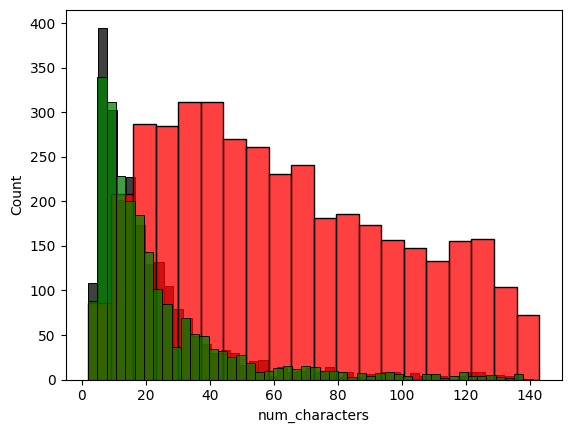

In [57]:
sns.histplot(df[df['target']==0]['num_characters'], color='black')
sns.histplot(df[df['target']==1]['num_characters'], color='red')
sns.histplot(df[df['target']==2]['num_characters'], color='green')

<Axes: xlabel='num_words', ylabel='Count'>

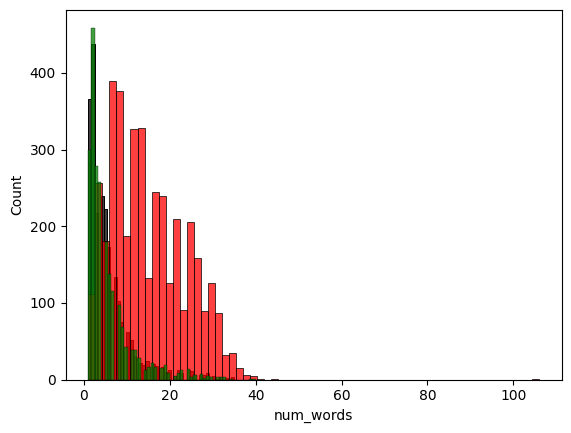

In [58]:
sns.histplot(df[df['target']==0]['num_words'], color='black')
sns.histplot(df[df['target']==1]['num_words'], color='red')
sns.histplot(df[df['target']==2]['num_words'], color='green')

<Axes: xlabel='num_sentences', ylabel='Count'>

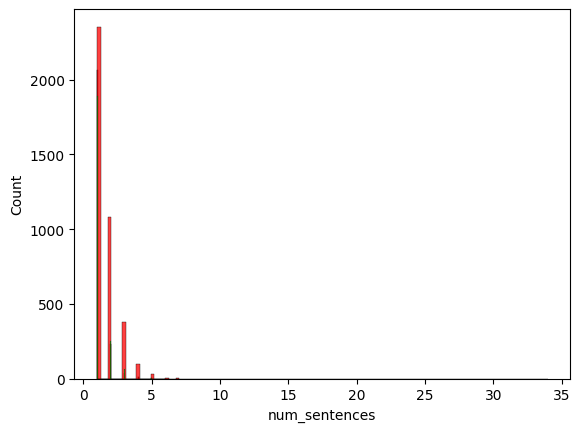

In [59]:
sns.histplot(df[df['target']==0]['num_sentences'], color='black')
sns.histplot(df[df['target']==1]['num_sentences'], color='red')
sns.histplot(df[df['target']==2]['num_sentences'], color='green')

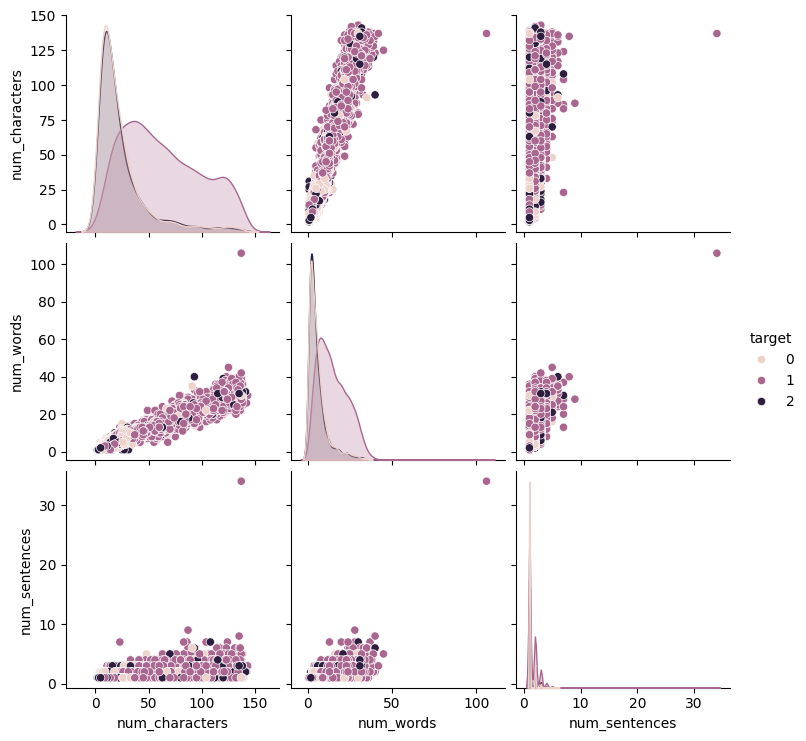

In [60]:
sns.pairplot(df, hue='target')

In [61]:
df.corr(numeric_only=True)

,target,num_characters,num_words,num_sentences
target,1.000000,0.011533,0.002996,0.029929
num_characters,0.011533,1.000000,0.967243,0.478668
num_words,0.002996,0.967243,1.000000,0.567793
num_sentences,0.029929,0.478668,0.567793,1.000000


<Axes: >

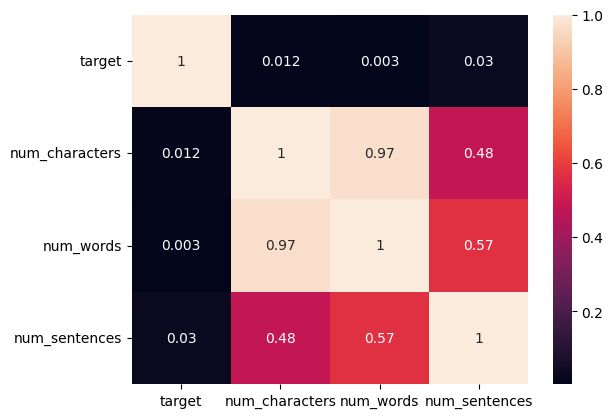

In [62]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

# 3. Data Preprocessing
* Lower case
* Tokenization
* Removing Special Characters
* Removing Stop words and punctuation
* Stemming

In [63]:
from nltk.corpus import stopwords
nltk.download('stopwords')
stopwords.words('english')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Vishwanath\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [64]:
import string

In [65]:
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()

In [66]:
def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)
    y = []
    for i in text:
        if i.isalnum():
            y.append(i)
    text = y[:]
    y.clear()
    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)
    text = y[:]
    y.clear()
    for i in text:
        y.append(ps.stem(i))
    return ' '.join(y)

In [67]:
df.head()['text'].values

array(['just watch evan longoria',
       'His beard is addressed in this week`s LOLs.',
       'Pretty amazing weekend so far  but its bedtime ,, I`m exhausted ! Mothers day tomorrow  nighty night',
       'SO frustrated!!', 'never'], dtype=object)

In [68]:
transform_text('Last session of the day  http://twitpic.com/67ezh')

'last session day http'

In [69]:
transform_text('Shanghai is also really exciting (precisely -- skyscrapers galore). Good tweeps in China:  (SH)  (BJ).')

'shanghai also realli excit precis skyscrap galor good tweep china sh bj'

In [70]:
df['text'].apply(transform_text)

0                                     watch evan longoria
1                                  beard address week lol
2       pretti amaz weekend far bedtim exhaust mother ...
3                                                frustrat
4                                                   never
                              ...                        
8535                                   thought go fun day
8536    total chill day relax garden love weather sham...
8537    love pink care today shall tweet hardcor work ...
8538         post photo robot ok offlin 4 hour ttfn oh im
8539           omg got explos new follow hello new follow
Name: text, Length: 8540, dtype: object

In [71]:
df['transformed_text'] = df['text'].apply(transform_text)

In [72]:
df.head()

,text,target,num_characters,num_words,num_sentences,transformed_text
0,just watch evan longoria,1,24,4,1,watch evan longoria
1,His beard is addressed in this week`s LOLs.,1,43,11,1,beard address week lol
2,Pretty amazing weekend so far but its bedtime...,1,100,20,2,pretti amaz weekend far bedtim exhaust mother ...
3,SO frustrated!!,0,15,4,2,frustrat
4,never,0,5,1,1,never


In [73]:
from wordcloud import WordCloud
wc = WordCloud(width=500, height=500, min_font_size=10, background_color='white')

In [74]:
negative_wc = wc.generate(df[df['target']==0]['transformed_text'].str.cat(sep=' '))

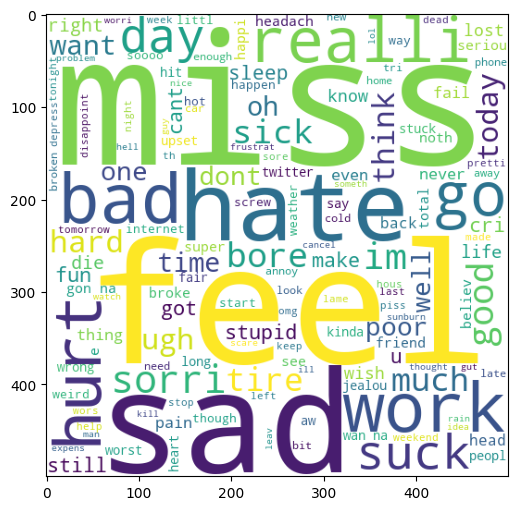

In [75]:
plt.figure(figsize=(15, 6))
plt.imshow(negative_wc)

In [76]:
neutral_wc = wc.generate(df[df['target']==1]['transformed_text'].str.cat(sep=' '))

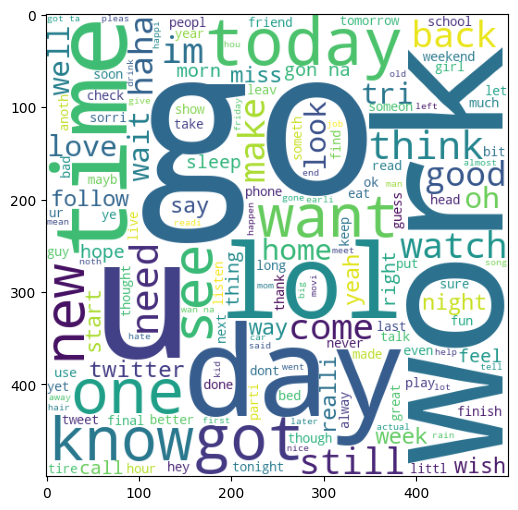

In [77]:
plt.figure(figsize=(15, 6))
plt.imshow(neutral_wc)

In [78]:
positive_wc = wc.generate(df[df['target']==2]['transformed_text'].str.cat(sep=' '))

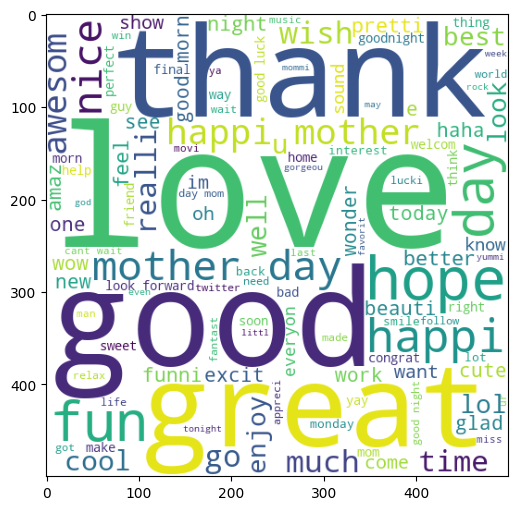

In [79]:
plt.figure(figsize=(15, 6))
plt.imshow(positive_wc)

In [80]:
df.head()

,text,target,num_characters,num_words,num_sentences,transformed_text
0,just watch evan longoria,1,24,4,1,watch evan longoria
1,His beard is addressed in this week`s LOLs.,1,43,11,1,beard address week lol
2,Pretty amazing weekend so far but its bedtime...,1,100,20,2,pretti amaz weekend far bedtim exhaust mother ...
3,SO frustrated!!,0,15,4,2,frustrat
4,never,0,5,1,1,never


In [81]:
negative_corpus = []
for msg in df[df['target']==0]['transformed_text'].to_list():
    for word in msg.split():
        negative_corpus.append(word)

In [82]:
len(negative_corpus)

6143

In [83]:
from collections import Counter
Counter(negative_corpus).most_common(30)

[('miss', 109),
 ('feel', 91),
 ('sad', 83),
 ('hate', 71),
 ('work', 66),
 ('bad', 66),
 ('sorri', 60),
 ('hurt', 59),
 ('realli', 58),
 ('go', 57),
 ('like', 57),
 ('day', 56),
 ('suck', 55),
 ('get', 54),
 ('im', 48),
 ('good', 45),
 ('bore', 41),
 ('sick', 39),
 ('tire', 37),
 ('much', 36),
 ('think', 32),
 ('hard', 32),
 ('today', 30),
 ('ugh', 30),
 ('want', 27),
 ('na', 27),
 ('got', 27),
 ('time', 26),
 ('oh', 26),
 ('one', 25)]

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29],
 [Text(0, 0, 'miss'),
  Text(1, 0, 'feel'),
  Text(2, 0, 'sad'),
  Text(3, 0, 'hate'),
  Text(4, 0, 'work'),
  Text(5, 0, 'bad'),
  Text(6, 0, 'sorri'),
  Text(7, 0, 'hurt'),
  Text(8, 0, 'realli'),
  Text(9, 0, 'go'),
  Text(10, 0, 'like'),
  Text(11, 0, 'day'),
  Text(12, 0, 'suck'),
  Text(13, 0, 'get'),
  Text(14, 0, 'im'),
  Text(15, 0, 'good'),
  Text(16, 0, 'bore'),
  Text(17, 0, 'sick'),
  Text(18, 0, 'tire'),
  Text(19, 0, 'much'),
  Text(20, 0, 'think'),
  Text(21, 0, 'hard'),
  Text(22, 0, 'today'),
  Text(23, 0, 'ugh'),
  Text(24, 0, 'want'),
  Text(25, 0, 'na'),
  Text(26, 0, 'got'),
  Text(27, 0, 'time'),
  Text(28, 0, 'oh'),
  Text(29, 0, 'one')])

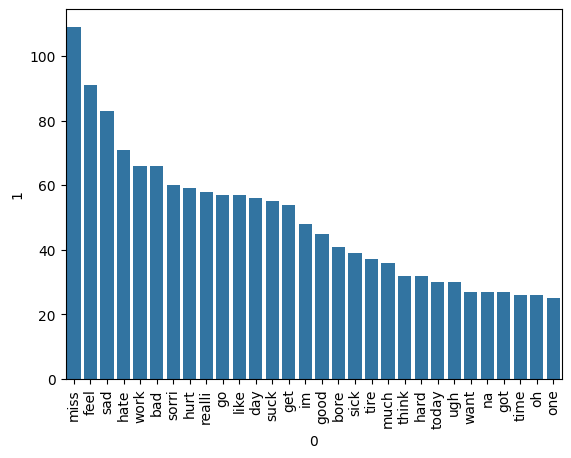

In [84]:
sns.barplot(x=pd.DataFrame(Counter(negative_corpus).most_common(30))[0], y=pd.DataFrame(Counter(negative_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')

In [85]:
neutral_corpus = []
for msg in df[df['target']==1]['transformed_text'].to_list():
    for word in msg.split():
        neutral_corpus.append(word)

In [86]:
len(neutral_corpus)

25774

In [87]:
Counter(neutral_corpus).most_common(30)

[('go', 359),
 ('get', 276),
 ('day', 242),
 ('work', 216),
 ('got', 200),
 ('time', 186),
 ('lol', 173),
 ('like', 164),
 ('today', 160),
 ('want', 155),
 ('know', 149),
 ('u', 146),
 ('one', 146),
 ('see', 145),
 ('back', 138),
 ('home', 127),
 ('think', 120),
 ('need', 119),
 ('new', 113),
 ('http', 112),
 ('watch', 110),
 ('night', 106),
 ('im', 102),
 ('make', 102),
 ('come', 100),
 ('last', 100),
 ('still', 100),
 ('good', 99),
 ('na', 97),
 ('look', 96)]

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29],
 [Text(0, 0, 'go'),
  Text(1, 0, 'get'),
  Text(2, 0, 'day'),
  Text(3, 0, 'work'),
  Text(4, 0, 'got'),
  Text(5, 0, 'time'),
  Text(6, 0, 'lol'),
  Text(7, 0, 'like'),
  Text(8, 0, 'today'),
  Text(9, 0, 'want'),
  Text(10, 0, 'know'),
  Text(11, 0, 'u'),
  Text(12, 0, 'one'),
  Text(13, 0, 'see'),
  Text(14, 0, 'back'),
  Text(15, 0, 'home'),
  Text(16, 0, 'think'),
  Text(17, 0, 'need'),
  Text(18, 0, 'new'),
  Text(19, 0, 'http'),
  Text(20, 0, 'watch'),
  Text(21, 0, 'night'),
  Text(22, 0, 'im'),
  Text(23, 0, 'make'),
  Text(24, 0, 'come'),
  Text(25, 0, 'last'),
  Text(26, 0, 'still'),
  Text(27, 0, 'good'),
  Text(28, 0, 'na'),
  Text(29, 0, 'look')])

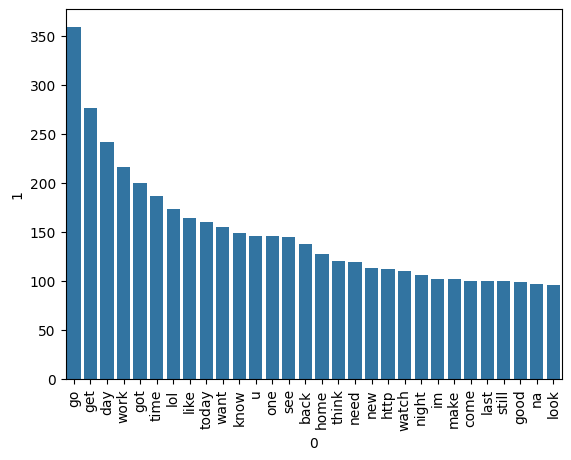

In [88]:
sns.barplot(x=pd.DataFrame(Counter(neutral_corpus).most_common(30))[0], y=pd.DataFrame(Counter(neutral_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')

In [89]:
positive_corpus = []
for msg in df[df['target']==2]['transformed_text'].to_list():
    for word in msg.split():
        positive_corpus.append(word)

In [90]:
len(positive_corpus)

6240

In [91]:
Counter(positive_corpus).most_common(30)

[('love', 225),
 ('good', 181),
 ('day', 154),
 ('happi', 132),
 ('thank', 115),
 ('great', 101),
 ('hope', 89),
 ('mother', 79),
 ('fun', 76),
 ('nice', 66),
 ('awesom', 56),
 ('like', 55),
 ('look', 46),
 ('wish', 45),
 ('much', 45),
 ('go', 45),
 ('time', 41),
 ('realli', 41),
 ('night', 41),
 ('feel', 38),
 ('cool', 37),
 ('morn', 37),
 ('better', 37),
 ('well', 35),
 ('best', 33),
 ('enjoy', 31),
 ('u', 31),
 ('lol', 31),
 ('pretti', 30),
 ('see', 30)]

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29],
 [Text(0, 0, 'love'),
  Text(1, 0, 'good'),
  Text(2, 0, 'day'),
  Text(3, 0, 'happi'),
  Text(4, 0, 'thank'),
  Text(5, 0, 'great'),
  Text(6, 0, 'hope'),
  Text(7, 0, 'mother'),
  Text(8, 0, 'fun'),
  Text(9, 0, 'nice'),
  Text(10, 0, 'awesom'),
  Text(11, 0, 'like'),
  Text(12, 0, 'look'),
  Text(13, 0, 'wish'),
  Text(14, 0, 'much'),
  Text(15, 0, 'go'),
  Text(16, 0, 'time'),
  Text(17, 0, 'realli'),
  Text(18, 0, 'night'),
  Text(19, 0, 'feel'),
  Text(20, 0, 'cool'),
  Text(21, 0, 'morn'),
  Text(22, 0, 'better'),
  Text(23, 0, 'well'),
  Text(24, 0, 'best'),
  Text(25, 0, 'enjoy'),
  Text(26, 0, 'u'),
  Text(27, 0, 'lol'),
  Text(28, 0, 'pretti'),
  Text(29, 0, 'see')])

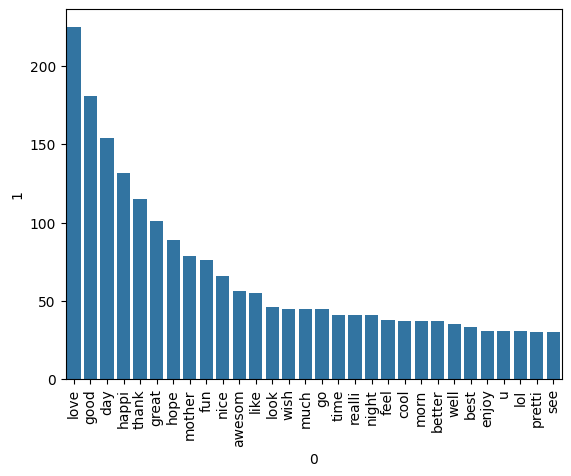

In [92]:
sns.barplot(x=pd.DataFrame(Counter(positive_corpus).most_common(30))[0], y=pd.DataFrame(Counter(positive_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')

# 4. Model Building

In [93]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer()

In [94]:
X = cv.fit_transform(df['transformed_text']).toarray()

In [95]:
X.shape

(8540, 7134)

In [96]:
y = df['target'].values

In [97]:
y

array([1, 1, 1, ..., 2, 1, 1], shape=(8540,))

In [98]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [99]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score
# use r2_socre for numerical or regression based and for classification use precision

In [100]:
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [101]:
gnb.fit(X_train, y_train)
y_pred1 = gnb.predict(X_test)
print('Accuracy', accuracy_score(y_test, y_pred1))
print('Confusion Matrix', confusion_matrix(y_test, y_pred1))
print('Precision', precision_score(y_test, y_pred1, average='weighted'))

Accuracy 0.5357142857142857
Confusion Matrix [[152  67 262]
 [126 408 256]
 [ 29  53 355]]
Precision 0.6008827309523861


In [102]:
mnb.fit(X_train, y_train)
y_pred2 = mnb.predict(X_test)
print('Accuracy', accuracy_score(y_test, y_pred2))
print('Confusion Matrix', confusion_matrix(y_test, y_pred2))
print('Precision', precision_score(y_test, y_pred2, average='weighted'))

Accuracy 0.6920374707259953
Confusion Matrix [[274 182  25]
 [ 87 631  72]
 [ 34 126 277]]
Precision 0.6956612373803208


In [103]:
bnb.fit(X_train, y_train)
y_pred3 = bnb.predict(X_test)
print('Accuracy', accuracy_score(y_test, y_pred3))
print('Confusion Matrix', confusion_matrix(y_test, y_pred3))
print('Precision', precision_score(y_test, y_pred3, average='weighted'))

Accuracy 0.7154566744730679
Confusion Matrix [[360  90  31]
 [149 539 102]
 [ 58  56 323]]
Precision 0.7239806381848339


In [104]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [105]:
tfidf = TfidfVectorizer()

In [106]:
X = tfidf.fit_transform(df['transformed_text']).toarray()

In [107]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [108]:
gnb.fit(X_train, y_train)
y_pred1 = gnb.predict(X_test)
print('Accuracy', accuracy_score(y_test, y_pred1))
print('Confusion Matrix', confusion_matrix(y_test, y_pred1))
print('Precision', precision_score(y_test, y_pred1, average='weighted'))

Accuracy 0.547423887587822
Confusion Matrix [[172  70 239]
 [134 411 245]
 [ 31  54 352]]
Precision 0.6067873215591958


In [109]:
mnb.fit(X_train, y_train)
y_pred2 = mnb.predict(X_test)
print('Accuracy', accuracy_score(y_test, y_pred2))
print('Confusion Matrix', confusion_matrix(y_test, y_pred2))
print('Precision', precision_score(y_test, y_pred2, average='weighted'))

Accuracy 0.6990632318501171
Confusion Matrix [[221 239  21]
 [ 37 718  35]
 [  6 176 255]]
Precision 0.7386432559486199


In [110]:
bnb.fit(X_train, y_train)
y_pred3 = bnb.predict(X_test)
print('Accuracy', accuracy_score(y_test, y_pred3))
print('Confusion Matrix', confusion_matrix(y_test, y_pred3))
print('Precision', precision_score(y_test, y_pred3, average='weighted'))

Accuracy 0.7154566744730679
Confusion Matrix [[360  90  31]
 [149 539 102]
 [ 58  56 323]]
Precision 0.7239806381848339


In [111]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

In [112]:
svc = SVC(kernel='sigmoid', gamma=1.0)
knc = KNeighborsClassifier()
mnb = MultinomialNB()
dtc = DecisionTreeClassifier(max_depth=5)
lrc = LogisticRegression(solver='liblinear', penalty='l1')
rfc = RandomForestClassifier(n_estimators=50, random_state=2)
abc = AdaBoostClassifier(n_estimators=50, random_state=2)
bc = BaggingClassifier(n_estimators=50, random_state=2)
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)
gdbt = GradientBoostingClassifier(n_estimators=50, random_state=2)
xgb = XGBClassifier(n_estimators=50, random_state=2)

In [113]:
clfs = {
    'SVC':svc,
    'KN':knc,
    'NB':mnb,
    'DT':dtc,
    'LR':lrc,
    'RF':rfc,
    'AdaBoost':abc,
    'BgC':bc,
    'ETC':etc,
    'GBDT': gdbt,
    'xgb': xgb
}

In [114]:
def train_classifier(clf, X_train, X_test, y_train, y_test):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    return accuracy, precision

In [115]:
train_classifier(svc , X_train, X_test, y_train, y_test)

(0.7265807962529274, 0.733489751526416)

In [116]:
accuracy_scores = []
precision_scores = []
for name, clf in clfs.items():
    current_accuracy, current_precision= train_classifier(clf, X_train, X_test, y_train, y_test)
    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)

C:\Users\Vishwanath\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(
C:\Users\Vishwanath\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [118]:
performance_df = pd.DataFrame({'Algorithm':clfs.keys(), 'Accuracy':accuracy_scores, 'Precision':precision_scores}).sort_values(['Precision', 'Accuracy'], ascending=False)

In [119]:
performance_df

,Algorithm,Accuracy,Precision
8,ETC,0.747658,0.754875
5,RF,0.738876,0.750869
7,BgC,0.730679,0.741008
2,NB,0.699063,0.738643
10,xgb,0.690281,0.734077
0,SVC,0.726581,0.733490
4,LR,0.707845,0.730286
9,GBDT,0.614754,0.711191
1,KN,0.419204,0.569665
3,DT,0.512295,0.526130


In [120]:
performance_df1 = pd.melt(performance_df, id_vars='Algorithm')

In [121]:
performance_df1

,Algorithm,variable,value
0,ETC,Accuracy,0.747658
1,RF,Accuracy,0.738876
2,BgC,Accuracy,0.730679
3,NB,Accuracy,0.699063
4,xgb,Accuracy,0.690281
5,SVC,Accuracy,0.726581
6,LR,Accuracy,0.707845
7,GBDT,Accuracy,0.614754
8,KN,Accuracy,0.419204
9,DT,Accuracy,0.512295


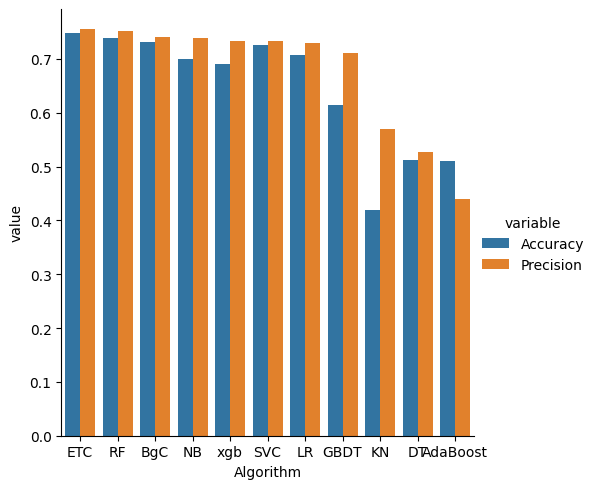

In [122]:
sns.catplot(x='Algorithm', y='value', hue='variable', data=performance_df1, kind='bar', height=5) 

In [123]:
tfidf = TfidfVectorizer(max_features=3000)

In [124]:
X = tfidf.fit_transform(df['transformed_text']).toarray()

In [125]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [126]:
gnb.fit(X_train, y_train)
y_pred1 = gnb.predict(X_test)
print(accuracy_score(y_test, y_pred1))
print(confusion_matrix(y_test, y_pred1))
print(precision_score(y_test, y_pred1, average='weighted'))

0.5608899297423887
[[197  70 214]
 [142 411 237]
 [ 33  54 350]]
0.6162582719694227


In [127]:
mnb.fit(X_train, y_train)
y_pred2 = mnb.predict(X_test)
print(accuracy_score(y_test, y_pred2))
print(confusion_matrix(y_test, y_pred2))
print(precision_score(y_test, y_pred2, average='weighted'))

0.7236533957845434
[[247 213  21]
 [ 43 707  40]
 [ 18 137 282]]
0.7455681544773549


In [128]:
bnb.fit(X_train, y_train)
y_pred3 = bnb.predict(X_test)
print(accuracy_score(y_test, y_pred3))
print(confusion_matrix(y_test, y_pred3))
print(precision_score(y_test, y_pred3, average='weighted'))

0.7259953161592506
[[370  78  33]
 [148 538 104]
 [ 60  45 332]]
0.7378510443741013


In [129]:
current_accuracy, current_precision = train_classifier(etc, X_train, X_test, y_train, y_test)
print(current_accuracy)
print(current_precision)

0.7488290398126464
0.7516536119917209


In [130]:
current_accuracy, current_precision = train_classifier(rfc, X_train, X_test, y_train, y_test)
print(current_accuracy)
print(current_precision)

0.7423887587822015
0.7443898971190593


In [131]:
current_accuracy, current_precision = train_classifier(bc, X_train, X_test, y_train, y_test)
print(current_accuracy)
print(current_precision)

0.7336065573770492
0.7362977047340986


In [132]:
tfidf = TfidfVectorizer(max_features=3000)

In [133]:
X = tfidf.fit_transform(df['transformed_text']).toarray()

In [134]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

In [135]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [136]:
gnb.fit(X_train, y_train)
y_pred1 = gnb.predict(X_test)
print(accuracy_score(y_test, y_pred1))
print(confusion_matrix(y_test, y_pred1))
print(precision_score(y_test, y_pred1, average='weighted'))

0.5567915690866511
[[193  74 214]
 [141 412 237]
 [ 33  58 346]]
0.6094693819876975


In [137]:
mnb.fit(X_train, y_train)
y_pred2 = mnb.predict(X_test)
print(accuracy_score(y_test, y_pred2))
print(confusion_matrix(y_test, y_pred2))
print(precision_score(y_test, y_pred2, average='weighted'))

0.7090163934426229
[[254 200  27]
 [ 61 663  66]
 [ 22 121 294]]
0.7182700270017359


In [138]:
bnb.fit(X_train, y_train)
y_pred3 = bnb.predict(X_test)
print(accuracy_score(y_test, y_pred3))
print(confusion_matrix(y_test, y_pred3))
print(precision_score(y_test, y_pred3, average='weighted'))

0.7259953161592506
[[370  78  33]
 [148 538 104]
 [ 60  45 332]]
0.7378510443741013


In [139]:
tfidf = TfidfVectorizer(max_features=3000)

In [140]:
X = tfidf.fit_transform(df['transformed_text']).toarray()

In [141]:
X = np.hstack((X, df['num_characters'].values.reshape(-1, 1)))

In [142]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [143]:
gnb.fit(X_train, y_train)
y_pred1 = gnb.predict(X_test)
print(accuracy_score(y_test, y_pred1))
print(confusion_matrix(y_test, y_pred1))
print(precision_score(y_test, y_pred1, average='weighted'))

0.5977751756440282
[[247  73 161]
 [147 431 212]
 [ 36  58 343]]
0.6390482514232664


In [144]:
mnb.fit(X_train, y_train)
y_pred2 = mnb.predict(X_test)
print(accuracy_score(y_test, y_pred2))
print(confusion_matrix(y_test, y_pred2))
print(precision_score(y_test, y_pred2, average='weighted'))

0.7230679156908665
[[222 239  20]
 [  7 772  11]
 [ 14 182 241]]
0.7832800790452031


In [145]:
bnb.fit(X_train, y_train)
y_pred3 = bnb.predict(X_test)
print(accuracy_score(y_test, y_pred3))
print(confusion_matrix(y_test, y_pred3))
print(precision_score(y_test, y_pred3, average='weighted'))

0.7259953161592506
[[370  78  33]
 [148 538 104]
 [ 60  45 332]]
0.7378510443741013


In [146]:
tfidf = TfidfVectorizer(max_features=3000)

In [147]:
X = tfidf.fit_transform(df['transformed_text']).toarray()

In [148]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [149]:
from sklearn.ensemble import VotingClassifier

In [150]:
rfc = RandomForestClassifier(n_estimators=50, random_state=2)
mnb = MultinomialNB()
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)

In [151]:
voting = VotingClassifier(estimators = [('rfc', rfc), ('mnb', mnb), ('etc', etc)])

In [152]:
voting.fit(X_train, y_train)
y_pred = voting.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(precision_score(y_test, y_pred, average='weighted'))

0.7540983606557377
[[344 110  27]
 [105 641  44]
 [ 62  72 303]]
0.7571089599582286


In [153]:
from sklearn.ensemble import StackingClassifier

In [154]:
estimators = [('rfc', rfc), ('mnb', mnb), ('etc', etc)]
final_estimator = RandomForestClassifier()
clf = StackingClassifier(estimators=estimators, final_estimator=final_estimator)

In [155]:
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

In [156]:
print('Accuracy', accuracy_score(y_test, y_pred))
print('Precision', precision_score(y_test, y_pred, average='weighted'))

Accuracy 0.7488290398126464
Precision 0.7478978220202823


In [157]:
# Voting Classifier balances accuracy and precision

In [158]:
tfidf = TfidfVectorizer()

In [159]:
X = tfidf.fit_transform(df['transformed_text']).toarray()

In [160]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [161]:
from sklearn.ensemble import VotingClassifier

In [162]:
rfc = RandomForestClassifier(n_estimators=50, random_state=2)
mnb = MultinomialNB()
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)

In [163]:
voting = VotingClassifier(estimators = [('rfc', rfc), ('mnb', mnb), ('etc', etc)])

In [164]:
voting.fit(X_train, y_train)
y_pred = voting.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(precision_score(y_test, y_pred, average='weighted'))

0.747072599531616
[[261 194  26]
 [ 42 712  36]
 [ 22 112 303]]
0.7620516651950748


In [165]:
# Voting Classifier balances accuracy and precision with max features 3000

In [166]:
tfidf = TfidfVectorizer(max_features=3000)

In [167]:
X = tfidf.fit_transform(df['transformed_text']).toarray()

In [168]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [169]:
from sklearn.ensemble import VotingClassifier

In [170]:
rfc = RandomForestClassifier(n_estimators=50, random_state=2)
mnb = MultinomialNB()
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)

In [171]:
voting = VotingClassifier(estimators = [('rfc', rfc), ('mnb', mnb), ('etc', etc)])

In [172]:
voting.fit(X_train, y_train)
y_pred = voting.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(precision_score(y_test, y_pred, average='weighted'))

0.7540983606557377
[[344 110  27]
 [105 641  44]
 [ 62  72 303]]
0.7571089599582286


In [173]:
import pickle
pickle.dump(tfidf, open('vectorizer.pkl', 'wb'))
pickle.dump(voting, open('model.pkl', 'wb'))